Additional (Model) Parameters:
    <br>
    * integration length: 5<br>
    * number of perturbed parameters: 10,000<br>
    * interval of perturbation: 10%<br>
    * number_of_output_variables: 6<br>
    * length_of_time_series_per_variable: 251<br>
    * integration_step: 0.02<br>

## Files Total Size

Parameters Size: $10,000 \times 12$<br>
Behavior Size: $10,000 \times 251 \times 6$ <br>
Tspan: 0:0.02:5.0

In [1]:
import scipy.io as spio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.patches as patches



import datafold.dynfold as dfold
import datafold.pcfold as pfold
from scipy.spatial.distance import pdist
from datafold.dynfold import LocalRegressionSelection


In [2]:
from datafold.dynfold import GeometricHarmonicsInterpolator as GHI

In [3]:
# plt.style.use('seaborn-white'); 
plt.rc('text', usetex=True); 
plt.rc('xtick', labelsize=16); 
plt.rc('ytick', labelsize=16);
plt.rc('axes', labelsize=20); 
plt.rc('font', family='serif');
plt.rc('font', family='serif') ;
plt.rcParams['image.cmap'] = 'Spectral'

np.random.seed(0)

In [4]:
Import_Data = spio.loadmat('../../Data/Model_output.mat', squeeze_me=True)
Output_Data = Import_Data['Behaviors']
Parameters = Import_Data['Parameter_values']

Output_Data.shape,Parameters.shape
del Import_Data

## Possible Effect Effective Parameters<br>

* D/H
* (xd-x1d)/T1d0
* (xq-x1q)/Tq10
* (x1d - x2d)/T1d0
* (x1q-x2q)/T2q0

#### Original Parameter Values <br>
[0:xdp,1:x1dp,3:x2dp,4:T1d0p,5:T2d0p,6:xqp,7:x1qp,8:x2qp,9:T1q0p,10:T2q0p,11:Hp,12:Dp]

In [5]:
Dict_Parameters = {}
Names_Parameters = ['xdp','x1dp','x2dp','T1d0p',
                    'T2d0p','xqp','x1qp','x2qp',
                    'T1q0p','T2q0p','Hp','Dp']

for i in range(0,len(Names_Parameters)):
    Dict_Parameters[Names_Parameters[i]] = Parameters[:,i]

In [6]:
Delta_Parameters = []
Delta_Names = []

### 0  deltax1 = (xd - xq)
Delta_Parameters.append(Dict_Parameters['xdp'] - Dict_Parameters['xqp'])
Delta_Names.append(r'$\delta x_1 $')

### 1 deltax2 = (xq - x1q)x
Delta_Parameters.append(Dict_Parameters['xqp'] - Dict_Parameters['x1qp'])
Delta_Names.append(r'$\delta x_2 $')

### 2 deltax3 = (x1q - x1d)
Delta_Parameters.append(Dict_Parameters['x1qp'] - Dict_Parameters['x1dp'])
Delta_Names.append(r'$\delta x_3 $')

### 3 deltax4 = (x1d - x2q)
Delta_Parameters.append(Dict_Parameters['x1dp'] - Dict_Parameters['x2qp'])
Delta_Names.append(r'$\delta x_4 $')

### 4 deltax5 = (x2q - x2d)
Delta_Parameters.append(Dict_Parameters['x2qp'] - Dict_Parameters['x2dp'])
Delta_Names.append(r'$\delta x_5 $')

### 5 deltaTd = (T1d0 - T2d0)
Delta_Parameters.append(Dict_Parameters['T1d0p'] - Dict_Parameters['T2d0p'])
Delta_Names.append(r'$\delta T_d $')

### 6 deltaTq = (T1q0 - T2q0)
Delta_Parameters.append(Dict_Parameters['T1q0p'] - Dict_Parameters['T2q0p'])
Delta_Names.append(r'$\delta T_q $')

### 7 x2d
Delta_Parameters.append(Dict_Parameters['x2dp'])
Delta_Names.append(r"$x_d^{''}$")

### 8 T2d0
Delta_Parameters.append(Dict_Parameters['T2d0p'])
Delta_Names.append(r"$T_{d0}^{''} $")

### 9 T2q0
Delta_Parameters.append(Dict_Parameters['T2q0p'])
Delta_Names.append(r"$T_{q0}^{''} $")

### 10 Hp
Delta_Parameters.append(Dict_Parameters['Hp'])
Delta_Names.append(r'$H$')

### 11 Dp
Delta_Parameters.append(Dict_Parameters['Dp'])
Delta_Names.append(r'$D$')

Delta_Parameters = np.array(Delta_Parameters).T

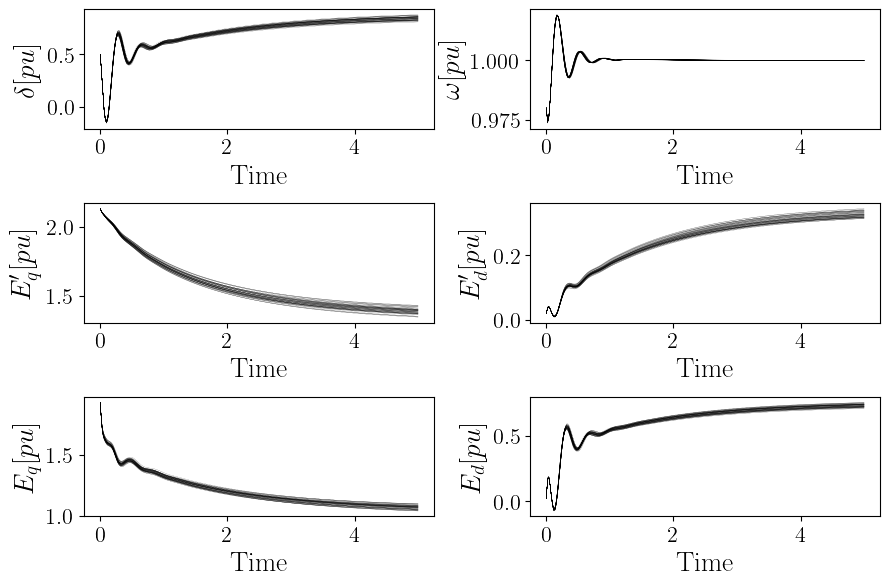

In [7]:
variables_names = [r'$\delta[pu]$',r'$\omega[pu]$',r"$E'_q[pu]$",r"$E'_d[pu]$",r'$E''_q[pu]$',r'$E''_d[pu]$']

fig = plt.figure(figsize=(3*3,3*2))
t_span = np.arange(0,5.02,0.02)
for i in range(0,6):
    ax = fig.add_subplot(3,2,i+1)
    for traj_i in range(0,50):
        ax.plot(t_span,Output_Data[traj_i,:,i],'k',linewidth = 0.1)
    ax.set_ylabel(variables_names[i])
    ax.set_xlabel('Time')
plt.tight_layout()

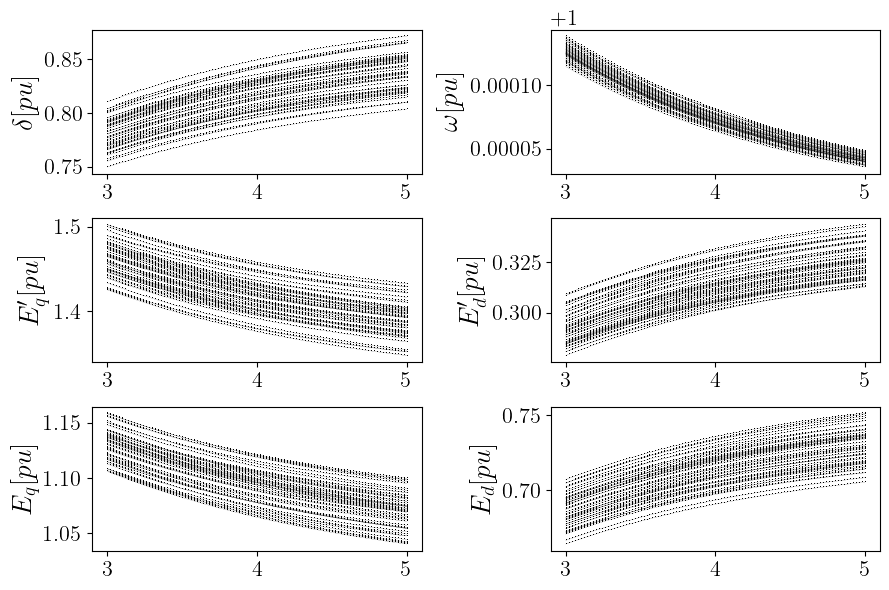

In [23]:
variables_names = [r'$\delta[pu]$',r'$\omega[pu]$',r"$E'_q[pu]$",r"$E'_d[pu]$",r'$E''_q[pu]$',r'$E''_d[pu]$']
t_i = 150
t_cut = 300
fig = plt.figure(figsize=(3*3,3*2))
t_span = np.arange(0,5.02,0.02)
for i in range(0,6):
    ax = fig.add_subplot(3,2,i+1)
    for traj_i in range(0,50):
        ax.plot(t_span[t_i:t_cut],Output_Data[traj_i,t_i:t_cut,i],'k,',linewidth = 0.1)
        ax.plot(t_span[t_i:t_cut],Output_Data[traj_i,t_i:t_cut,i],'k',linewidth = 0.1)

    ax.set_ylabel(variables_names[i])
    
plt.tight_layout()


In [8]:
t_span.shape

(251,)

### Reshape Data to have the outputs concatentated

In [24]:
# np.savetxt('../../Data/Parameters.csv', Parameters, delimiter=',')

In [25]:
# np.savetxt('../../Data/Delta_Parameters.csv', Delta_Parameters, delimiter=',')

In [26]:
Data = Output_Data[:,t_i:t_cut,:][:,::,:].reshape(10000,-1)

In [27]:
Data =((Data-np.min(Data,axis=0))/(np.max(Data,axis=0)-np.min(Data,axis=0)))

In [28]:
# np.savetxt('../../Data/Behavior_Rescaled.csv',Data,delimiter=',')

In [29]:
X_pcm = pfold.PCManifold(Data)
X_pcm.optimize_parameters()

print(f"epsilon={X_pcm.kernel.epsilon}, cut-off={X_pcm.cut_off}")

epsilon=0.14749609785350695, cut-off=1.64832597793586


In [30]:
## Epsilon Computation:

In [31]:
N =np.median(pdist(Data))**2
N*8

220.54699692579507

In [32]:
n_eigenpairs = 31

dmap = dfold.DiffusionMaps(
    kernel=pfold.GaussianKernel(epsilon=N*8, distance=dict(cut_off=np.inf)),
    n_eigenpairs=n_eigenpairs,
)



dmap = dmap.fit(X_pcm)
evecs, evals = dmap.eigenvectors_, dmap.eigenvalues_

In [33]:
selection = LocalRegressionSelection(
    intrinsic_dim=6
    , n_subsample=1000, strategy="dim"
).fit(dmap.eigenvectors_)
print(f"Found parsimonious eigenvectors (indices): {selection.evec_indices_}")

Found parsimonious eigenvectors (indices): [ 1  2  3  5  6 17]


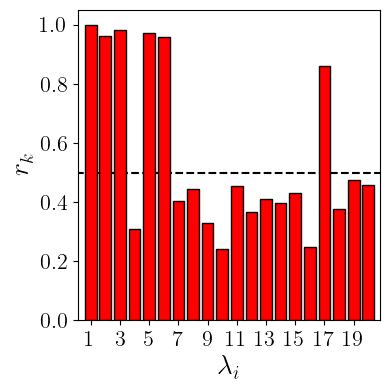

In [74]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(111)
ax.bar(np.arange(0,21),selection.residuals_[:21],color='red',edgecolor = 'black')
ax.set_ylabel(r'$r_k$')
ax.set_xlabel(r'$\lambda_{i}$')

# Set x-ticks at the desired positions
ax.set_xticks(np.arange(1, 21, 2))

ax.hlines(0.5,0,21,linestyles='dashed',zorder=0,color='k')
# ax.grid(True)
plt.tight_layout()
ax.set_xlim([0.1,20.8])

plt.savefig('../../Figures/Power_System_Local_Linear.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_System_Local_Linear.pdf',bbox_inches='tight')

In [35]:
Phi = evecs[:,selection.evec_indices_]
Phi.shape

(10000, 6)

#### Geometric Harmonics

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
Phi =((Phi-np.min(Phi,axis=0))/(np.max(Phi,axis=0)-np.min(Phi,axis=0)))
Parameters=((Delta_Parameters-np.min(Delta_Parameters,axis=0))/(np.max(Delta_Parameters,axis=0)-np.min(Delta_Parameters,axis=0)))

/var/folders/z0/xjmx8k611cqfkqpfsf86jcqc0000gn/T/ipykernel_6133/638913626.py:2: RuntimeWarning: invalid value encountered in divide
  Parameters=((Delta_Parameters-np.min(Delta_Parameters,axis=0))/(np.max(Delta_Parameters,axis=0)-np.min(Delta_Parameters,axis=0)))


In [38]:
Parameters[:,4] = 0

In [ ]:
## Uncomment to save the file used by 2_Geometric_Harmonics_Deltas.ipynb: [Phi, rescaled identifiable parameters]
# np.save('../../Data/Phis_Parameters.npy',[Phi,Parameters[:,[1,2,3,5,6,7]]])

In [39]:
Phi_train, Phi_test, Parameters_train, Parameters_test = \
        train_test_split(  Phi, Parameters, test_size=0.2, random_state=0)

#### Fit Original Parameters

In [40]:
# compute the geometric harmonics from X to \Psi
n_eigenpairs = 300
epsilon = np.median(pdist(Phi_train)**2)

# construct the GeometricHarmonicsInterpolator and fit it to the data.
gh_interpolant = GHI(
    pfold.GaussianKernel(epsilon=epsilon),
    n_eigenpairs=n_eigenpairs,
)

gh_interpolant.fit(Phi_train, Parameters_train);

In [41]:
gh_interpolant.eigenvalues_[-1]

0.0036294965531692243

In [42]:
Parameters_predict_train = gh_interpolant.predict(Phi_train)
Parameters_predict_test = gh_interpolant.predict(Phi_test)

In [43]:
%matplotlib inline

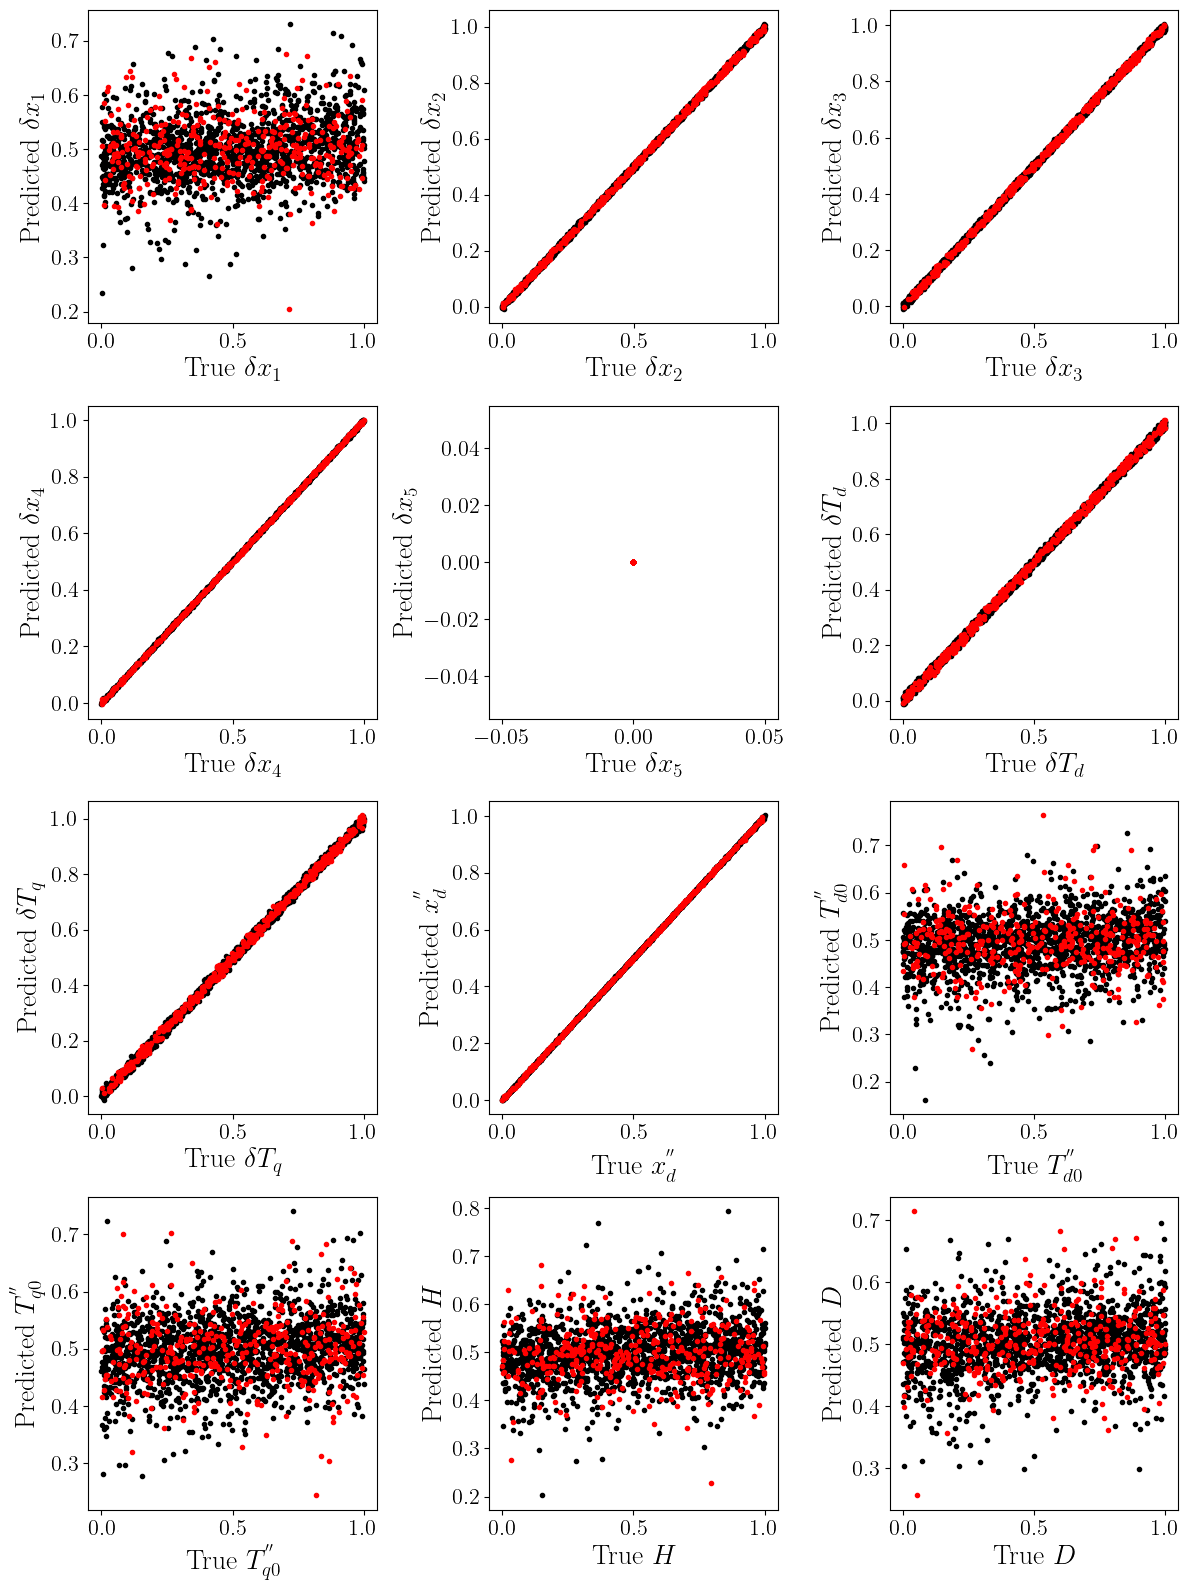

In [76]:
fig =plt.figure(figsize=(3*4,4*4))
for i in range(0,12):
    ax = fig.add_subplot(4,3,i+1)
    ax.plot(Parameters_train[::5,i],Parameters_predict_train[::5,i],'k.')
    ax.plot(Parameters_test[::5,i],Parameters_predict_test[::5,i],'r.')
    label_x = 'True  ' + Delta_Names[i]
    ax.set_xlabel(label_x)
    label_y = 'Predicted ' + Delta_Names[i]
    ax.set_ylabel(label_y)
    
plt.tight_layout()
plt.savefig('../../Figures/Power_Systems_GH_parity_plots.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_Systems_GH_parity_plots.pdf',bbox_inches='tight')

In [77]:
absolute_pointwise_error = np.abs(Parameters_predict_test - Parameters_test) #/ np.abs(Parameters_test);
absolute_pointwise_error.shape

absolute_pointwise_error[:,4] = np.inf

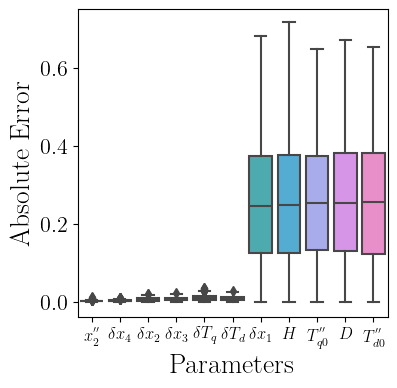

In [79]:
# data = pd.DataFrame(absolute_pointwise_error, columns=[
#     r'$\delta x_1 $', r'$\delta x_2 $', r'$\delta x_3 $', r'$\delta x_4 $', 
#     r'$\delta x_5 $', r'$\delta T_d $', r'$\delta T_q $', r"$x_2^{''}$", 
#     r"$T_{d0}^{''} $", r"$T_{q0}^{''} $", r'$H$', r'$D$'
# ])

# ## Replace infinite values with NaN and drop them
# absolute_pointwise_error[~np.isfinite(absolute_pointwise_error)] = np.nan

# # Create a DataFrame to facilitate plotting with seaborn
# data = pd.DataFrame(absolute_pointwise_error, columns=[
#     r'$\delta x_1 $', r'$\delta x_2 $', r'$\delta x_3 $', r'$\delta x_4 $', 
#     r'$\delta x_5 $', r'$\delta T_d $', r'$\delta T_q $', r"$x_2^{''}$", 
#     r"$T_{d0}^{''} $", r"$T_{q0}^{''} $", r'$H$', r'$D$'
# ])

# # Drop columns with all NaN values
# data = data.dropna(axis=1, how='all')

# # Calculate the median of relative errors for each parameter
# medians = data.median().sort_values()

# # Sort the data based on the medians
# sorted_data = data[medians.index]

# # Melt the DataFrame for seaborn
# melted_data = sorted_data.melt(var_name='Parameters', value_name='Absolute Error')


# # Creating the box plots
# fig = plt.figure(figsize=(4, 4))
# ax = fig.add_subplot(111)
# sns.boxplot(x='Parameters', y='Absolute Error', data=melted_data, ax=ax)
# # Rotating x-axis labels for better readability
# ax.set_xticklabels(ax.get_xticklabels(),fontsize=12)

# # Coordinates of rectangle vertices
# # in clockwise order
# # xs = [-0.3, 5.5, 5.5, -0.3, -0.3]
# # ys = [-0.03, -0.03, 0.06, 0.06, -0.03]
# # ax.plot(xs, ys, color="red")

# # ax.text(2.7, 0.072, "Identifiable Parameters", color="red", fontsize=12.5, ha="center")
# ax.set_ylim([-0.04,0.75])

# plt.savefig('../../Figures/Power_System_GH_Box_Plots_Parameters.png',dpi=300,bbox_inches='tight')
# plt.savefig('../../Figures/Power_System_GH_Box_Plots_Parameters.pdf',bbox_inches='tight')

### Possible one-to-one

In [47]:
# Param_One_To_One = Delta_Parameters[:,[1,2,3,5,6,7]]
# Param_One_To_One.shape

(10000, 6)

In [48]:
# Phi =((Phi-np.min(Phi,axis=0))/(np.max(Phi,axis=0)-np.min(Phi,axis=0)))
# Param_One_To_One=((Param_One_To_One-np.min(Param_One_To_One,axis=0))/(np.max(Param_One_To_One,axis=0)-np.min(Param_One_To_One,axis=0)))

In [49]:
# Phi_train, Phi_test, Param_One_Train, Param_One_Test = \
#         train_test_split(  Phi, Param_One_To_One, test_size=0.2, random_state=0)

In [50]:
# Phi_train.shape,Phi_test.shape,Param_One_Train.shape,Param_One_Test.shape

((8000, 6), (2000, 6), (8000, 6), (2000, 6))

In [51]:
# # compute the geometric harmonics from X to \Psi
# n_eigenpairs = 300

# epsilon = np.median(pdist(Param_One_Train)**2)

# # construct the GeometricHarmonicsInterpolator and fit it to the data.
# gh_interpolant_one_ = GHI(
#     pfold.GaussianKernel(epsilon=epsilon),
#     n_eigenpairs=n_eigenpairs,
# )

# gh_interpolant_one_.fit(Param_One_Train, Phi_train);

In [52]:
# gh_interpolant_one_.eigenvalues_[-1]

0.0033969211071611487

In [53]:
# phis_predict_train = gh_interpolant_one_.predict(Param_One_Train)
# phis_predict_test = gh_interpolant_one_.predict(Param_One_Test)

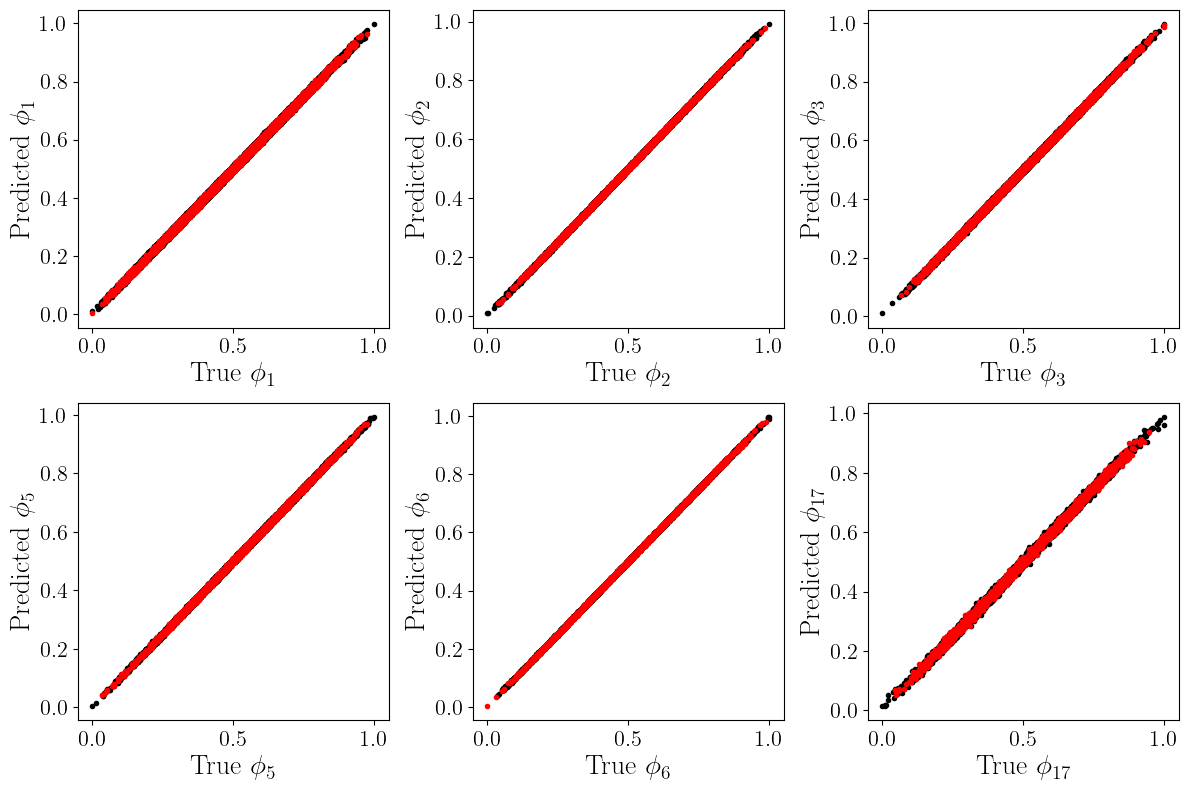

In [54]:
# fig =plt.figure(figsize=(3*4,2*4))
# for i in range(0,6):
#     ax = fig.add_subplot(2,3,i+1)
#     ax.plot(Phi_train[:,i],phis_predict_train[:,i],'k.')
#     ax.plot(Phi_test[:,i],phis_predict_test[:,i],'r.')
#     # Using LaTeX formatting for subscripts
#     label_x = r'True ' + r'$\phi_{' + str(selection.evec_indices_[i]) + r'}$';
#     ax.set_xlabel(label_x);
#     label_y = r'Predicted ' + r'$\phi_{' + str(selection.evec_indices_[i]) + r'}$';
#     ax.set_ylabel(label_y);
    
# plt.tight_layout()
# plt.savefig('../../Figures/Regression_Phis_.png',dpi=300,bbox_inches='tight')
# plt.savefig('../../Figures/Regression_Phis_.pdf',bbox_inches='tight')

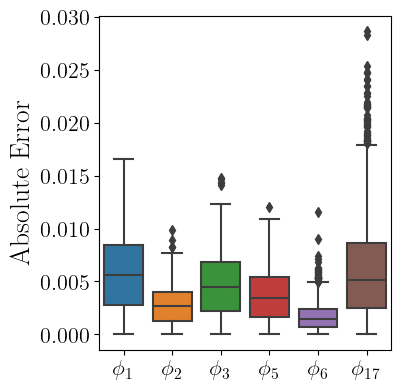

In [55]:
# test_errors = np.abs(Phi_test - phis_predict_test)

# # Prepare data for box plot
# data = []
# labels = []
# for i in range(6):
#     data.append(test_errors[:, i])
#     labels.append(r'$\phi_{' + str(selection.evec_indices_[i]) + r'}$')

# # Creating the box plot
# fig = plt.figure(figsize=(4, 4))
# ax = fig.add_subplot(111)
# sns.boxplot(data=data, ax=ax)

# # Setting x-axis labels
# ax.set_xticklabels(labels)

# # Setting the y-axis label
# ax.set_ylabel('Absolute Error')

# # Adding a title

# # Rotating x-axis labels for better readability
# ax.set_xticklabels(ax.get_xticklabels())

# # Showing the plot
# plt.tight_layout()

# plt.savefig('../../Figures/Power_System_GH_Box_Plots_Phis.png',dpi=300,bbox_inches='tight')
# plt.savefig('../../Figures/Power_System_GH_Box_Plots_Phis.pdf',bbox_inches='tight')

In [73]:
# # Identifiable_Deltas_Names  = [Delta_Names[1:3] + Delta_Names[4:8]]
# np.save('../../Data/PowerSystem_Delta_Identifiable_Parameters_Phis.npy',[[Phi],[Param_One_To_One]])#,[Identifiable_Deltas_Names]])

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (3, 1) + inhomogeneous part.

In [70]:
# [Delta_Names[1:3] + Delta_Names[4:8]]

[['$\\delta x_2 $',
  '$\\delta x_3 $',
  '$\\delta x_5 $',
  '$\\delta T_d $',
  '$\\delta T_q $',
  "$x_2^{''}$"]]